# Klasifikasi Multilabel: GoEmotions

Dataset GoEmotions berisi 58k komentar Reddit yang diberi anotasi 27 kategori emosi plus 1 kategori netral (total 28 label emosi). Satu komentar pengguna dapat mengekspresikan campuran beberapa emosi sekaligus. Data ini diambil dari Hugging Face Hub menggunakan pustaka `datasets`.

- Nama dataset: GoEmotions (konfigurasi: `simplified`)
- Sumber data: Hugging Face Datasets (`google-research-datasets/go_emotions`)
- Link repositori: https://huggingface.co/datasets/google-research-datasets/go_emotions
- Jumlah baris data asli:
  - Split `train`: 43.410 baris
  - Split `validation`: 5.426 baris
  - Split `test`: 5.427 baris
  - Total baris: 54.263 baris
- Binarisasi: Kolom `labels` (list id emosi) dibinarisasi menjadi matriks biner 28 kolom menggunakan `MultiLabelBinarizer`

In [1]:
import pandas as pd
from datasets import load_dataset
from sklearn.preprocessing import MultiLabelBinarizer

dataset_dict = load_dataset("google-research-datasets/go_emotions", "simplified")

print("Jumlah baris asli tiap split:")
for split_name in dataset_dict:
    print(f"  Split '{split_name}': {len(dataset_dict[split_name]):,} baris")
total_original_rows = sum(len(dataset_dict[s]) for s in dataset_dict)
print(f"Total baris asli: {total_original_rows:,} baris\n")

df_train = pd.DataFrame(dataset_dict["train"])
emotion_names = dataset_dict["train"].features["labels"].feature.names
n_emotions = len(emotion_names)

mlb = MultiLabelBinarizer(classes=range(n_emotions))
labels_binary = mlb.fit_transform(df_train["labels"])
df_labels = pd.DataFrame(labels_binary, columns=emotion_names)

df = pd.concat([df_train[["id", "text"]], df_labels], axis=1)
target_cols = emotion_names

print("Shape data train setelah binarisasi:", df.shape)
display(df.head())
print("\nTipe data:")
print(df.dtypes)

Jumlah baris asli tiap split:
  Split 'train': 43,410 baris
  Split 'validation': 5,426 baris
  Split 'test': 5,427 baris
Total baris asli: 54,263 baris



Shape data train setelah binarisasi: (43410, 30)


,id,text,admiration,amusement,anger,annoyance,approval,caring,confusion,curiosity,...,love,nervousness,optimism,pride,realization,relief,remorse,sadness,surprise,neutral
0,eebbqej,My favourite food is anything I didn't have to...,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
1,ed00q6i,"Now if he does off himself, everyone will thin...",0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
2,eezlygj,WHY THE FUCK IS BAYLESS ISOING,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,ed7ypvh,To make her feel threatened,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,ed0bdzj,Dirty Southern Wankers,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0



Tipe data:
id                  str
text                str
admiration        int64
amusement         int64
anger             int64
annoyance         int64
approval          int64
caring            int64
confusion         int64
curiosity         int64
desire            int64
disappointment    int64
disapproval       int64
disgust           int64
embarrassment     int64
excitement        int64
fear              int64
gratitude         int64
grief             int64
joy               int64
love              int64
nervousness       int64
optimism          int64
pride             int64
realization       int64
relief            int64
remorse           int64
sadness           int64
surprise          int64
neutral           int64
dtype: object


Jumlah label            : 28
Label cardinality       : 1.177  (rata-rata label per baris)
Label density           : 0.042
Baris dengan >1 label   : 16.4%
Baris tanpa label       : 0.0%
=> Multilabel


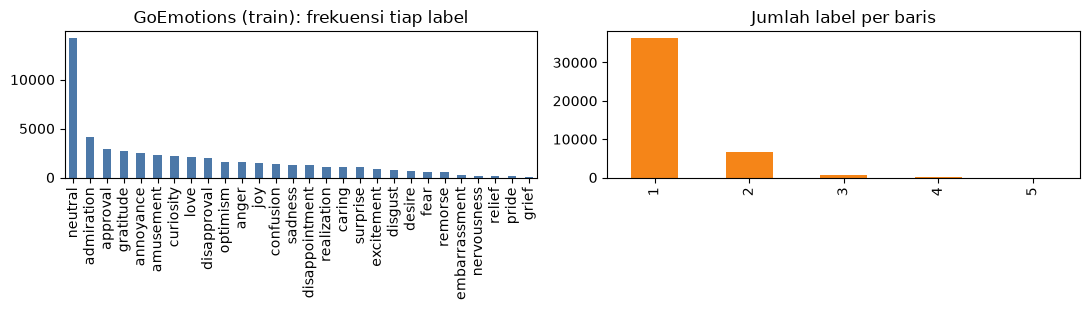

In [2]:
import matplotlib.pyplot as plt

def check_multilabel(Y, title):
    Y = pd.DataFrame(Y)
    per_row = Y.sum(axis=1)
    print(f"Jumlah label            : {Y.shape[1]}")
    print(f"Label cardinality       : {per_row.mean():.3f}  (rata-rata label per baris)")
    print(f"Label density           : {per_row.mean() / Y.shape[1]:.3f}")
    print(f"Baris dengan >1 label   : {(per_row > 1).mean():.1%}")
    print(f"Baris tanpa label       : {(per_row == 0).mean():.1%}")
    print("=> Multilabel" if (per_row > 1).any() else "=> Bukan multilabel (tidak ada baris dengan >1 label)")
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
    Y.sum().sort_values(ascending=False).plot(kind="bar", ax=axes[0], color="#4C78A8")
    axes[0].set_title(f"{title}: frekuensi tiap label")
    per_row.value_counts().sort_index().plot(kind="bar", ax=axes[1], color="#F58518")
    axes[1].set_title("Jumlah label per baris")
    plt.tight_layout()
    plt.show()

check_multilabel(df[target_cols], "GoEmotions (train)")

In [3]:
assert len(target_cols) == 28, f"Jumlah label harus 28, didapat: {len(target_cols)}"
assert (df[target_cols].sum(axis=1) > 1).sum() > 0, "Harus terdapat baris dengan lebih dari 1 label"
assert df[target_cols].sum(axis=1).mean() > 1.0, "Label cardinality harus > 1.0"
assert df.shape == (43410, 30), f"Bentuk dataframe tidak sesuai: {df.shape}"

for col in target_cols:
    assert set(df[col].unique()).issubset({0, 1}), f"Kolom target {col} harus bernilai biner 0/1"

print("Semua verifikasi lolos.")

Semua verifikasi lolos.


## Kesimpulan

Dataset GoEmotions terbukti merupakan klasifikasi multilabel:
1. Jumlah baris data asli:
   - Split `train`: 43.410 baris
   - Split `validation`: 5.426 baris
   - Split `test`: 5.427 baris
   - Total data asli: 54.263 baris
2. Setiap komentar teks dapat memiliki lebih dari satu dari 28 kategori emosi secara bersamaan.
3. Terdapat 7.102 komentar (16,36% dari data train) yang memiliki lebih dari satu label emosi aktif.
4. Nilai label cardinality sebesar 1,1772 dengan label density 0,0420.